# Tree-Based Models for 30-Day Readmission Prediction

## Objective

This notebook evaluates tree-based machine learning models for predicting
30-day hospital readmission.

The models will be compared against the Logistic Regression baseline using:

- ROC-AUC
- PR-AUC
- Precision
- Recall
- F1 Score
- Confusion Matrix

A patient-level train/test split is used to prevent encounters from the same
patient appearing in both the training and testing datasets.

In [24]:
#IMPORTING LIBRARIES
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

pd.set_option("display.max_columns", None)

RANDOM_STATE = 42

## 1. Load Engineered Clinical Features

In [2]:
DATA_PATH = Path("../data/processed/clinical_features.csv")

df = pd.read_csv(DATA_PATH)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

df.head()

Rows: 101,766
Columns: 29


,patient_id,encounter_id,age_midpoint,gender,race,admission_type,admission_source,discharge_disposition,length_of_stay,previous_inpatient_visits,previous_outpatient_visits,previous_emergency_visits,primary_diagnosis,secondary_diagnosis,tertiary_diagnosis,diagnosis_count,lab_procedure_count,procedure_count,medication_count,hba1c_result,glucose_result,insulin_status,diabetes_medication,readmitted_30_days,primary_diagnosis_category,secondary_diagnosis_category,tertiary_diagnosis_category,total_previous_visits,has_previous_inpatient_visit
0,8222157,2278392,5,Female,Caucasian,Unmapped:6,Physician Referral,Not Mapped,1,0,0,0,250.83,NaN,NaN,1,41,0,1,NaN,NaN,No,No,False,Diabetes,Other,Other,0,0
1,55629189,149190,15,Female,Caucasian,Emergency,Emergency Room,Discharged to home,3,0,0,0,276,250.01,255,9,59,0,18,NaN,NaN,Up,Yes,False,Endocrine,Diabetes,Endocrine,0,0
2,86047875,64410,25,Female,AfricanAmerican,Emergency,Emergency Room,Discharged to home,2,1,2,0,648,250,V27,6,11,5,13,NaN,NaN,No,Yes,False,Pregnancy,Diabetes,Supplementary,3,1
3,82442376,500364,35,Male,Caucasian,Emergency,Emergency Room,Discharged to home,2,0,0,0,8,250.43,403,7,44,1,16,NaN,NaN,Up,Yes,False,Infectious,Diabetes,Circulatory,0,0
4,42519267,16680,45,Male,Caucasian,Emergency,Emergency Room,Discharged to home,1,0,0,0,197,157,250,5,51,0,8,NaN,NaN,Steady,Yes,False,Neoplasms,Neoplasms,Diabetes,0,0


In [ ]:
# Target variable distribution

TARGET = "readmitted_30_days"

print("Target distribution:")
print(df[TARGET].value_counts())

print("\nTarget distribution (%):")
print(
    df[TARGET]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Target distribution:
readmitted_30_days
False    90409
True     11357
Name: count, dtype: int64

Target distribution (%):
readmitted_30_days
False    88.84
True     11.16
Name: proportion, dtype: float64


## 2. Model Feature Selection

The same leakage-safe feature set used for the Logistic Regression baseline
is retained to ensure a fair comparison between models.

In [4]:
model_features = [
    "age_midpoint",
    "gender",
    "race",
    "admission_type",
    "admission_source",
    "discharge_disposition",
    "length_of_stay",
    "previous_inpatient_visits",
    "previous_outpatient_visits",
    "previous_emergency_visits",
    "diagnosis_count",
    "lab_procedure_count",
    "procedure_count",
    "medication_count",
    "hba1c_result",
    "glucose_result",
    "insulin_status",
    "diabetes_medication",
    "primary_diagnosis_category",
    "secondary_diagnosis_category",
    "tertiary_diagnosis_category",
    "total_previous_visits",
    "has_previous_inpatient_visit",
]

X = df[model_features].copy()
y = df[TARGET].astype(int)
groups = df["patient_id"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Unique patients:", groups.nunique())

X shape: (101766, 23)
y shape: (101766,)
Unique patients: 71518


## 3. Patient-Level Train/Test Split

To prevent data leakage, encounters belonging to the same patient must not
appear in both the training and testing datasets.

A group-based split is therefore performed using `patient_id`.

In [5]:
# Patient-level train/test split

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

train_idx, test_idx = next(
    splitter.split(
        X,
        y,
        groups=groups
    )
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

train_groups = groups.iloc[train_idx]
test_groups = groups.iloc[test_idx]

print("Training encounters:", len(X_train))
print("Testing encounters:", len(X_test))

print("\nTraining patients:", train_groups.nunique())
print("Testing patients:", test_groups.nunique())

Training encounters: 81613
Testing encounters: 20153

Training patients: 57214
Testing patients: 14304


In [6]:
# Verifying that no patient appears in both datasets

train_patient_ids = set(train_groups)
test_patient_ids = set(test_groups)

patient_overlap = train_patient_ids.intersection(test_patient_ids)

print("Patients appearing in BOTH sets:", len(patient_overlap))

assert len(patient_overlap) == 0, "Patient leakage detected!"

print("✓ No patient-level leakage detected.")

Patients appearing in BOTH sets: 0
✓ No patient-level leakage detected.


In [7]:
# Checking class distribution across overall, training, and testing sets

print("Overall readmission rate:")
print(round(y.mean(), 4))

print("\nTraining readmission rate:")
print(round(y_train.mean(), 4))

print("\nTesting readmission rate:")
print(round(y_test.mean(), 4))

print("\nTraining class counts:")
print(y_train.value_counts())

print("\nTesting class counts:")
print(y_test.value_counts())

Overall readmission rate:
0.1116

Training readmission rate:
0.1128

Testing readmission rate:
0.1067

Training class counts:
readmitted_30_days
0    72407
1     9206
Name: count, dtype: int64

Testing class counts:
readmitted_30_days
0    18002
1     2151
Name: count, dtype: int64


## 4. Preprocessing Pipeline

Categorical and numerical variables require different preprocessing before
they can be supplied to the machine learning models.

Categorical variables will be imputed and one-hot encoded, while numerical
variables will be imputed using their median values.

In [8]:
categorical_features = X_train.select_dtypes(
    include=["object", "string"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

print("Categorical features:", len(categorical_features))
print(categorical_features)

print("\nNumerical features:", len(numerical_features))
print(numerical_features)

print("\nTotal features:",
      len(categorical_features) + len(numerical_features))

Categorical features: 12
['gender', 'race', 'admission_type', 'admission_source', 'discharge_disposition', 'hba1c_result', 'glucose_result', 'insulin_status', 'diabetes_medication', 'primary_diagnosis_category', 'secondary_diagnosis_category', 'tertiary_diagnosis_category']

Numerical features: 11
['age_midpoint', 'length_of_stay', 'previous_inpatient_visits', 'previous_outpatient_visits', 'previous_emergency_visits', 'diagnosis_count', 'lab_procedure_count', 'procedure_count', 'medication_count', 'total_previous_visits', 'has_previous_inpatient_visit']

Total features: 23


## 5. Preprocessing for Tree-Based Models

Categorical variables are imputed using the most frequent value and then
one-hot encoded.

Numerical variables are imputed using the median.

Feature scaling is not required because tree-based models make decisions
using feature thresholds rather than distances or coefficient magnitudes.

In [9]:
# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

# Numerical preprocessing
numerical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

# Combine both transformations
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_transformer,
            categorical_features
        ),
        (
            "numerical",
            numerical_transformer,
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## 6. Decision Tree Baseline

A Decision Tree classifier is trained as the first non-linear model.

The tree is intentionally constrained to reduce severe overfitting.
Class weighting is used because 30-day readmissions represent only about
11% of the dataset.

In [10]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(
    max_depth=6,
    min_samples_leaf=50,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

decision_tree_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", decision_tree)
    ]
)

decision_tree_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, def

In [11]:
# TRAINING DECISION TREE MODEL
decision_tree_pipeline.fit(
    X_train,
    y_train
)

print("Decision Tree training complete.")

Decision Tree training complete.


In [12]:
# GENERATING PREDICTIONS
# Class predictions
y_pred_tree = decision_tree_pipeline.predict(X_test)

# Probability of 30-day readmission
y_prob_tree = decision_tree_pipeline.predict_proba(X_test)[:, 1]

print("Predictions generated:", len(y_pred_tree))
print("Probability predictions generated:", len(y_prob_tree))

print("\nFirst 10 predicted probabilities:")
print(y_prob_tree[:10])

Predictions generated: 20153
Probability predictions generated: 20153

First 10 predicted probabilities:
[0.45923197 0.43733818 0.43733818 0.37544295 0.32012498 0.3929002
 0.25621255 0.62482312 0.41548557 0.32012498]


In [13]:
#EVALUATING DECISION TREE
tree_accuracy = accuracy_score(
    y_test,
    y_pred_tree
)

tree_precision = precision_score(
    y_test,
    y_pred_tree,
    zero_division=0
)

tree_recall = recall_score(
    y_test,
    y_pred_tree
)

tree_f1 = f1_score(
    y_test,
    y_pred_tree
)

tree_roc_auc = roc_auc_score(
    y_test,
    y_prob_tree
)

tree_pr_auc = average_precision_score(
    y_test,
    y_prob_tree
)

print("DECISION TREE RESULTS")
print("---------------------")
print("Accuracy:", round(tree_accuracy, 4))
print("Precision:", round(tree_precision, 4))
print("Recall:", round(tree_recall, 4))
print("F1 Score:", round(tree_f1, 4))
print("ROC-AUC:", round(tree_roc_auc, 4))
print("PR-AUC:", round(tree_pr_auc, 4))

DECISION TREE RESULTS
---------------------
Accuracy: 0.6371
Precision: 0.1607
Recall: 0.5681
F1 Score: 0.2505
ROC-AUC: 0.6491
PR-AUC: 0.1821


In [14]:
# CONFUSION MATRIX

tree_cm = confusion_matrix(
    y_test,
    y_pred_tree
)

print("Decision Tree Confusion Matrix:")
print(tree_cm)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_tree,
        digits=4
    )
)

Decision Tree Confusion Matrix:
[[11618  6384]
 [  929  1222]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9260    0.6454    0.7606     18002
           1     0.1607    0.5681    0.2505      2151

    accuracy                         0.6371     20153
   macro avg     0.5433    0.6067    0.5056     20153
weighted avg     0.8443    0.6371    0.7062     20153



## 7. Random Forest Model

A Random Forest classifier is trained to determine whether an ensemble
of decision trees can improve discrimination of 30-day readmission risk.

The model uses class weighting to account for the imbalanced target.
Performance will be evaluated on the same patient-level holdout set used
for the Logistic Regression and Decision Tree models.

In [15]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=20,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", random_forest)
    ]
)

random_forest_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, def

In [16]:
# TRAINING THE MODEL
random_forest_pipeline.fit(
    X_train,
    y_train
)

print("Random Forest training complete.")

Random Forest training complete.


In [17]:
#GENERATING PREDICTIONS

y_pred_rf = random_forest_pipeline.predict(X_test)

y_prob_rf = random_forest_pipeline.predict_proba(
    X_test
)[:, 1]

print("Predictions:", len(y_pred_rf))
print("Probabilities:", len(y_prob_rf))

print("\nFirst 10 probabilities:")
print(y_prob_rf[:10])

Predictions: 20153
Probabilities: 20153

First 10 probabilities:
[0.49927559 0.37247281 0.43451564 0.4296171  0.37167364 0.35738042
 0.30461578 0.65623292 0.43851112 0.35882678]


In [18]:
# EVALUATING THE RANDOM FOREST MODEL

rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

rf_precision = precision_score(
    y_test,
    y_pred_rf,
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    y_pred_rf
)

rf_f1 = f1_score(
    y_test,
    y_pred_rf
)

rf_roc_auc = roc_auc_score(
    y_test,
    y_prob_rf
)

rf_pr_auc = average_precision_score(
    y_test,
    y_prob_rf
)

print("RANDOM FOREST RESULTS")
print("---------------------")
print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1 Score:", round(rf_f1, 4))
print("ROC-AUC:", round(rf_roc_auc, 4))
print("PR-AUC:", round(rf_pr_auc, 4))

RANDOM FOREST RESULTS
---------------------
Accuracy: 0.6478
Precision: 0.1695
Recall: 0.5895
F1 Score: 0.2632
ROC-AUC: 0.6681
PR-AUC: 0.2045


In [19]:
#CONFUSION MATRIX

rf_cm = confusion_matrix(
    y_test,
    y_pred_rf
)

print("Random Forest Confusion Matrix:")
print(rf_cm)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_rf,
        digits=4
    )
)

Random Forest Confusion Matrix:
[[11787  6215]
 [  883  1268]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9303    0.6548    0.7686     18002
           1     0.1695    0.5895    0.2632      2151

    accuracy                         0.6478     20153
   macro avg     0.5499    0.6221    0.5159     20153
weighted avg     0.8491    0.6478    0.7146     20153



## 8. Model Comparison

The Logistic Regression, Decision Tree, and Random Forest models are
compared using the same patient-level holdout dataset.

Because 30-day readmission is an imbalanced classification problem,
accuracy alone is not sufficient. Particular attention is given to
recall, F1 score, ROC-AUC, and PR-AUC.

In [21]:
# Baseline results from 02_baseline_model.ipynb
# Recorded here so all models can be compared in this notebook.

balanced_accuracy = 0.6650
balanced_precision = 0.1716
balanced_recall = 0.5588
balanced_f1 = 0.2626
balanced_roc_auc = 0.6669
balanced_pr_auc = 0.2057

In [22]:
model_comparison = pd.DataFrame({
    "Model": [
        "Balanced Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        balanced_accuracy,
        tree_accuracy,
        rf_accuracy
    ],
    "Precision": [
        balanced_precision,
        tree_precision,
        rf_precision
    ],
    "Recall": [
        balanced_recall,
        tree_recall,
        rf_recall
    ],
    "F1": [
        balanced_f1,
        tree_f1,
        rf_f1
    ],
    "ROC-AUC": [
        balanced_roc_auc,
        tree_roc_auc,
        rf_roc_auc
    ],
    "PR-AUC": [
        balanced_pr_auc,
        tree_pr_auc,
        rf_pr_auc
    ]
})

model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Balanced Logistic Regression,0.6650,0.1716,0.5588,0.2626,0.6669,0.2057
1,Decision Tree,0.6371,0.1607,0.5681,0.2505,0.6491,0.1821
2,Random Forest,0.6478,0.1695,0.5895,0.2632,0.6681,0.2045


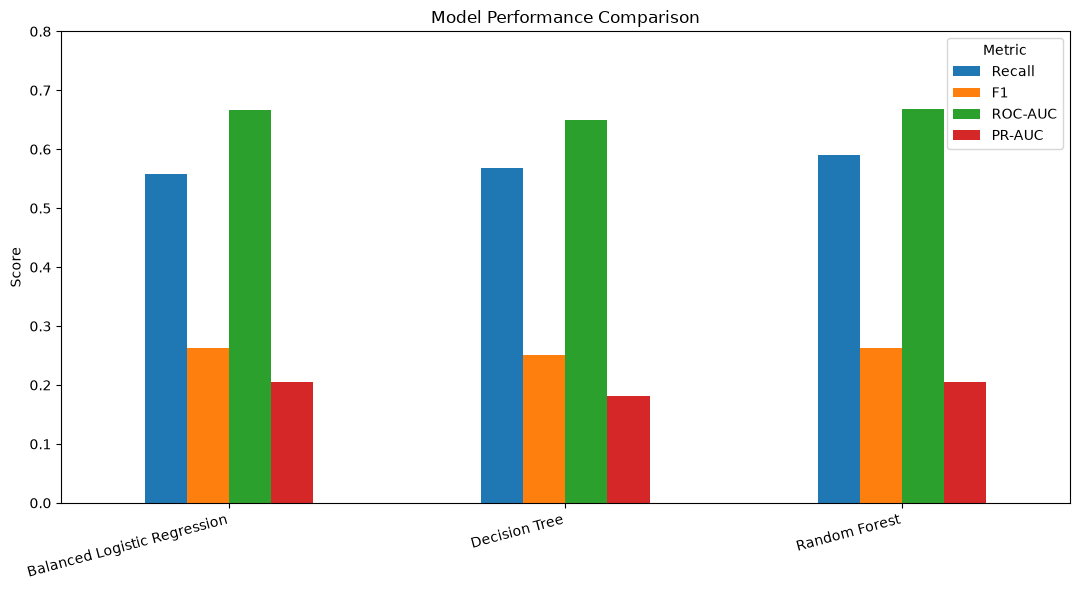

In [25]:
comparison_plot = model_comparison.set_index("Model")[
    ["Recall", "F1", "ROC-AUC", "PR-AUC"]
]

ax = comparison_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("")
plt.ylim(0, 0.8)
plt.xticks(rotation=15, ha="right")
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

### Interpretation

The three models show broadly similar predictive performance.

- Random Forest achieved the highest recall (0.5895), identifying the largest proportion of 30-day readmissions.
- Random Forest also produced the highest ROC-AUC (0.6681), although the improvement over balanced Logistic Regression (0.6669) was very small.
- Balanced Logistic Regression achieved the highest PR-AUC (0.2057), slightly outperforming Random Forest (0.2045).
- The Decision Tree performed worse on ROC-AUC and PR-AUC, suggesting that a single tree does not capture the predictive structure as effectively as the ensemble or linear model.

These results indicate that increasing model complexity from Logistic Regression to Random Forest has not substantially improved discrimination. The next experiment therefore evaluates gradient boosting to determine whether more sophisticated nonlinear interactions can improve 30-day readmission prediction.

## 9. Gradient Boosting — XGBoost

XGBoost is evaluated as a more powerful nonlinear model for predicting
30-day hospital readmission.

Unlike the previous baseline experiments, model selection will be performed
using a validation set derived only from the training patients. The existing
test set remains untouched until the final model configuration has been selected.

This prevents the test set from influencing model development and provides a
more reliable estimate of generalization performance.

In [26]:
# XGBoost Classifier and GroupShuffleSplit Import

from xgboost import XGBClassifier
from sklearn.model_selection import GroupShuffleSplit

In [27]:
# Split the existing training data into:
# model-training data and validation data.
#
# GroupShuffleSplit ensures that encounters belonging to the same
# patient cannot appear in both subsets.

validation_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_sub_idx, val_idx = next(
    validation_split.split(
        X_train,
        y_train,
        groups=train_groups
    )
)

X_train_sub = X_train.iloc[train_sub_idx].copy()
X_val = X_train.iloc[val_idx].copy()

y_train_sub = y_train.iloc[train_sub_idx].copy()
y_val = y_train.iloc[val_idx].copy()

train_sub_groups = train_groups.iloc[train_sub_idx]
val_groups = train_groups.iloc[val_idx]

print("Training encounters:", len(X_train_sub))
print("Validation encounters:", len(X_val))

print("\nTraining patients:", train_sub_groups.nunique())
print("Validation patients:", val_groups.nunique())

print("\nTraining readmission rate:")
print(round(y_train_sub.mean(), 4))

print("\nValidation readmission rate:")
print(round(y_val.mean(), 4))

Training encounters: 65146
Validation encounters: 16467

Training patients: 45771
Validation patients: 11443

Training readmission rate:
0.1125

Validation readmission rate:
0.114


In [28]:
# Check for patient-level overlap across train, validation, and test sets

train_sub_patient_ids = set(train_sub_groups)
val_patient_ids = set(val_groups)
test_patient_ids = set(test_groups)

train_val_overlap = train_sub_patient_ids.intersection(val_patient_ids)
train_test_overlap = train_sub_patient_ids.intersection(test_patient_ids)
val_test_overlap = val_patient_ids.intersection(test_patient_ids)

print("Train ↔ Validation overlap:", len(train_val_overlap))
print("Train ↔ Test overlap:", len(train_test_overlap))
print("Validation ↔ Test overlap:", len(val_test_overlap))

assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

print("\n✓ No patient-level leakage across train, validation, and test sets.")

Train ↔ Validation overlap: 0
Train ↔ Test overlap: 0
Validation ↔ Test overlap: 0

✓ No patient-level leakage across train, validation, and test sets.


In [29]:
# Identify categorical and numerical features for XGBoost

categorical_features_xgb = X_train_sub.select_dtypes(
    include=["object", "string"]
).columns.tolist()

numerical_features_xgb = X_train_sub.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

print("Categorical features:", len(categorical_features_xgb))
print("Numerical features:", len(numerical_features_xgb))
print(
    "Total:",
    len(categorical_features_xgb) + len(numerical_features_xgb)
)

Categorical features: 12
Numerical features: 11
Total: 23


In [30]:
# Preprocessing pipelines for numerical and categorical features for XGBoost

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numeric_transformer_xgb = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer_xgb = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocessor_xgb = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer_xgb,
            numerical_features_xgb
        ),
        (
            "cat",
            categorical_transformer_xgb,
            categorical_features_xgb
        )
    ]
)

In [31]:
# Calculate the scale_pos_weight for XGBoost based on class imbalance in the training set

negative_count = (y_train_sub == 0).sum()
positive_count = (y_train_sub == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative cases:", negative_count)
print("Positive cases:", positive_count)
print("scale_pos_weight:", round(scale_pos_weight, 3))

Negative cases: 57817
Positive cases: 7329
scale_pos_weight: 7.889


## 10. Initial XGBoost Model

The first XGBoost model is trained using the training subset only.

Class imbalance is handled using `scale_pos_weight`, calculated from the
ratio of negative to positive training examples.

Model performance is evaluated on the validation set. The final test set
remains untouched during model development.

In [32]:
# XGBoost model training with preprocessing pipeline

from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_xgb),
        ("model", xgb_model)
    ]
)

print("Training XGBoost...")

xgb_pipeline.fit(
    X_train_sub,
    y_train_sub
)

print("✓ XGBoost training complete.")

Training XGBoost...
✓ XGBoost training complete.


In [34]:
# Evaluation metrics for model performance

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Probability that each validation encounter belongs to class 1
xgb_val_prob = xgb_pipeline.predict_proba(X_val)[:, 1]

print("Predicted probabilities:", len(xgb_val_prob))
print("Minimum probability:", round(xgb_val_prob.min(), 4))
print("Maximum probability:", round(xgb_val_prob.max(), 4))
print("Mean probability:", round(xgb_val_prob.mean(), 4))

Predicted probabilities: 16467
Minimum probability: 0.0054
Maximum probability: 0.9137
Mean probability: 0.4527


In [35]:
# XGBoost validation metrics calculation and display

initial_threshold = 0.50

xgb_val_pred = (
    xgb_val_prob >= initial_threshold
).astype(int)

xgb_accuracy = accuracy_score(
    y_val,
    xgb_val_pred
)

xgb_precision = precision_score(
    y_val,
    xgb_val_pred,
    zero_division=0
)

xgb_recall = recall_score(
    y_val,
    xgb_val_pred
)

xgb_f1 = f1_score(
    y_val,
    xgb_val_pred
)

xgb_roc_auc = roc_auc_score(
    y_val,
    xgb_val_prob
)

xgb_pr_auc = average_precision_score(
    y_val,
    xgb_val_prob
)

print("XGBOOST VALIDATION RESULTS")
print("--------------------------")
print("Threshold:", initial_threshold)
print("Accuracy:", round(xgb_accuracy, 4))
print("Precision:", round(xgb_precision, 4))
print("Recall:", round(xgb_recall, 4))
print("F1 Score:", round(xgb_f1, 4))
print("ROC-AUC:", round(xgb_roc_auc, 4))
print("PR-AUC:", round(xgb_pr_auc, 4))

XGBOOST VALIDATION RESULTS
--------------------------
Threshold: 0.5
Accuracy: 0.6572
Precision: 0.1845
Recall: 0.5871
F1 Score: 0.2808
ROC-AUC: 0.6766
PR-AUC: 0.234


In [36]:
# XGBoost validation confusion matrix and classification report

xgb_cm = confusion_matrix(
    y_val,
    xgb_val_pred
)

print("XGBoost Validation Confusion Matrix:")
print(xgb_cm)

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        xgb_val_pred,
        digits=4
    )
)

XGBoost Validation Confusion Matrix:
[[9720 4870]
 [ 775 1102]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9262    0.6662    0.7750     14590
           1     0.1845    0.5871    0.2808      1877

    accuracy                         0.6572     16467
   macro avg     0.5553    0.6267    0.5279     16467
weighted avg     0.8416    0.6572    0.7186     16467



## 12. Decision Threshold Analysis

The default classification threshold of 0.50 is not necessarily optimal
for identifying patients at risk of 30-day readmission.

Different thresholds create different trade-offs between:

- Recall: proportion of actual readmissions identified.
- Precision: proportion of flagged patients who are actually readmitted.
- False negatives: readmitted patients missed by the model.
- False positives: patients flagged unnecessarily.

Threshold selection is performed using the validation set only.
The test set remains untouched.

In [37]:
# XGBoost validation metrics across multiple thresholds

import pandas as pd

thresholds = [
    0.20, 0.25, 0.30, 0.35,
    0.40, 0.45, 0.50, 0.55,
    0.60, 0.65, 0.70
]

threshold_results = []

for threshold in thresholds:

    predictions = (
        xgb_val_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions
        ),
        "F1": f1_score(
            y_val, predictions
        ),
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn,
        "Patients Flagged": tp + fp
    })

xgb_threshold_df = pd.DataFrame(
    threshold_results
)

xgb_threshold_df.round(4)

,Threshold,Precision,Recall,F1,True Positives,False Positives,False Negatives,Patients Flagged
0,0.20,0.1174,0.9968,0.2101,1871,14066,6,15937
1,0.25,0.1208,0.9877,0.2153,1854,13490,23,15344
2,0.30,0.1270,0.9584,0.2243,1799,12364,78,14163
3,0.35,0.1352,0.8972,0.2350,1684,10769,193,12453
4,0.40,0.1483,0.8151,0.2510,1530,8784,347,10314
5,0.45,0.1621,0.7043,0.2635,1322,6835,555,8157
6,0.50,0.1845,0.5871,0.2808,1102,4870,775,5972
7,0.55,0.2080,0.4576,0.2860,859,3270,1018,4129
8,0.60,0.2319,0.3378,0.2750,634,2100,1243,2734
9,0.65,0.2626,0.2270,0.2435,426,1196,1451,1622


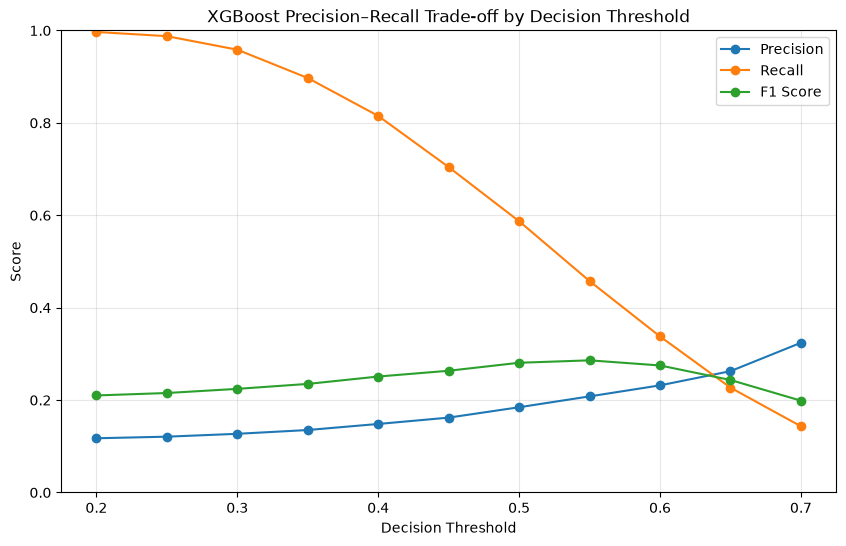

In [38]:
# XGBoost validation metrics visualization across multiple thresholds

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    xgb_threshold_df["Threshold"],
    xgb_threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    xgb_threshold_df["Threshold"],
    xgb_threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    xgb_threshold_df["Threshold"],
    xgb_threshold_df["F1"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title(
    "XGBoost Precision–Recall Trade-off by Decision Threshold"
)

plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()

plt.show()

In [39]:
# XGBoost best threshold by F1 score

best_f1_row = xgb_threshold_df.loc[
    xgb_threshold_df["F1"].idxmax()
]

print("BEST THRESHOLD BY F1")
print("--------------------")
print(
    "Threshold:",
    best_f1_row["Threshold"]
)
print(
    "Precision:",
    round(best_f1_row["Precision"], 4)
)
print(
    "Recall:",
    round(best_f1_row["Recall"], 4)
)
print(
    "F1:",
    round(best_f1_row["F1"], 4)
)
print(
    "Patients flagged:",
    int(best_f1_row["Patients Flagged"])
)
print(
    "False negatives:",
    int(best_f1_row["False Negatives"])
)

BEST THRESHOLD BY F1
--------------------
Threshold: 0.55
Precision: 0.208
Recall: 0.4576
F1: 0.286
Patients flagged: 4129
False negatives: 1018


## 13. Controlled XGBoost Hyperparameter Experiment

The initial XGBoost model provides a strong tree-based benchmark.

A small set of candidate configurations is evaluated on the validation
set to determine whether model discrimination can be improved without
performing an unnecessarily large hyperparameter search.

The primary comparison metrics are:

- ROC-AUC
- PR-AUC
- Recall
- Precision
- F1 score

PR-AUC is particularly important because 30-day readmission is the
minority class.

The test set remains untouched during model selection.

In [41]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd


xgb_configs = [
    {
        "name": "Initial",
        "n_estimators": 300,
        "max_depth": 4,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },
    {
        "name": "Shallow",
        "n_estimators": 400,
        "max_depth": 3,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },
    {
        "name": "Conservative",
        "n_estimators": 500,
        "max_depth": 3,
        "learning_rate": 0.03,
        "subsample": 0.9,
        "colsample_bytree": 0.9
    }
]

tuning_results = []
tuned_models = {}

for config in xgb_configs:

    print(f"Training: {config['name']}")

    classifier = XGBClassifier(
        n_estimators=config["n_estimators"],
        max_depth=config["max_depth"],
        learning_rate=config["learning_rate"],
        subsample=config["subsample"],
        colsample_bytree=config["colsample_bytree"],
        scale_pos_weight=scale_pos_weight,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    # IMPORTANT:
    # Reuse the preprocessing transformer we already created
    model = Pipeline([
        ("preprocessor", preprocessor_xgb),
        ("classifier", classifier)
    ])

    model.fit(
        X_train_sub,
        y_train_sub
    )

    val_prob = model.predict_proba(X_val)[:, 1]

    # Current validation reference threshold
    val_pred = (val_prob >= 0.55).astype(int)

    tuning_results.append({
        "Model": config["name"],

        "ROC-AUC": roc_auc_score(
            y_val,
            val_prob
        ),

        "PR-AUC": average_precision_score(
            y_val,
            val_prob
        ),

        "Precision": precision_score(
            y_val,
            val_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_val,
            val_pred
        ),

        "F1": f1_score(
            y_val,
            val_pred
        )
    })

    # Save complete fitted pipeline
    tuned_models[config["name"]] = model


tuning_df = pd.DataFrame(tuning_results)

tuning_df.round(4)

Training: Initial
Training: Shallow
Training: Conservative


,Model,ROC-AUC,PR-AUC,Precision,Recall,F1
0,Initial,0.6759,0.2332,0.2072,0.4544,0.2847
1,Shallow,0.6773,0.2371,0.2053,0.4630,0.2845
2,Conservative,0.6760,0.2373,0.2053,0.4560,0.2832


## 14. Final Model Selection

Three XGBoost configurations were compared using the validation set.

The Shallow XGBoost configuration was selected because it achieved the
highest validation ROC-AUC while maintaining competitive PR-AUC, recall,
and F1 score.

Selected configuration:

- `n_estimators = 400`
- `max_depth = 3`
- `learning_rate = 0.05`
- `subsample = 0.8`
- `colsample_bytree = 0.8`
- class imbalance handled using `scale_pos_weight`

The model configuration is now locked.

The untouched test set will be used once to estimate final generalization
performance.

In [ ]:
# Final model selection and threshold setting

final_model = tuned_models["Shallow"]

FINAL_THRESHOLD = 0.55

print("Final model: Shallow XGBoost")
print("Decision threshold:", FINAL_THRESHOLD)



Final model: Shallow XGBoost
Decision threshold: 0.55


In [43]:
# Predict on the final test set

final_test_prob = final_model.predict_proba(X_test)[:, 1]

final_test_pred = (
    final_test_prob >= FINAL_THRESHOLD
).astype(int)

In [44]:
# Evaluate the final model on the test set

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

final_accuracy = accuracy_score(
    y_test,
    final_test_pred
)

final_precision = precision_score(
    y_test,
    final_test_pred,
    zero_division=0
)

final_recall = recall_score(
    y_test,
    final_test_pred
)

final_f1 = f1_score(
    y_test,
    final_test_pred
)

final_roc_auc = roc_auc_score(
    y_test,
    final_test_prob
)

final_pr_auc = average_precision_score(
    y_test,
    final_test_prob
)

print("FINAL TEST RESULTS")
print("----------------------------")
print("Threshold:", FINAL_THRESHOLD)
print("Accuracy:", round(final_accuracy, 4))
print("Precision:", round(final_precision, 4))
print("Recall:", round(final_recall, 4))
print("F1 Score:", round(final_f1, 4))
print("ROC-AUC:", round(final_roc_auc, 4))
print("PR-AUC:", round(final_pr_auc, 4))

FINAL TEST RESULTS
----------------------------
Threshold: 0.55
Accuracy: 0.7388
Precision: 0.192
Recall: 0.451
F1 Score: 0.2693
ROC-AUC: 0.6705
PR-AUC: 0.2102


In [45]:
# Confusion matrix and classification report for the final model

final_cm = confusion_matrix(
    y_test,
    final_test_pred
)

print("FINAL TEST CONFUSION MATRIX")
print("----------------------------")
print(final_cm)

tn, fp, fn, tp = final_cm.ravel()

print("\nTrue Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

print("\nCLASSIFICATION REPORT")
print("----------------------------")

print(
    classification_report(
        y_test,
        final_test_pred,
        digits=4
    )
)

FINAL TEST CONFUSION MATRIX
----------------------------
[[13919  4083]
 [ 1181   970]]

True Negatives : 13919
False Positives: 4083
False Negatives: 1181
True Positives : 970

CLASSIFICATION REPORT
----------------------------
              precision    recall  f1-score   support

           0     0.9218    0.7732    0.8410     18002
           1     0.1920    0.4510    0.2693      2151

    accuracy                         0.7388     20153
   macro avg     0.5569    0.6121    0.5551     20153
weighted avg     0.8439    0.7388    0.7800     20153



In [46]:
# Compare the generalization performance of the final model on the validation and test sets

generalization_comparison = pd.DataFrame({
    "Dataset": [
        "Validation",
        "Test"
    ],

    "ROC-AUC": [
        tuning_df.loc[
            tuning_df["Model"] == "Shallow",
            "ROC-AUC"
        ].iloc[0],
        final_roc_auc
    ],

    "PR-AUC": [
        tuning_df.loc[
            tuning_df["Model"] == "Shallow",
            "PR-AUC"
        ].iloc[0],
        final_pr_auc
    ],

    "Precision": [
        tuning_df.loc[
            tuning_df["Model"] == "Shallow",
            "Precision"
        ].iloc[0],
        final_precision
    ],

    "Recall": [
        tuning_df.loc[
            tuning_df["Model"] == "Shallow",
            "Recall"
        ].iloc[0],
        final_recall
    ],

    "F1": [
        tuning_df.loc[
            tuning_df["Model"] == "Shallow",
            "F1"
        ].iloc[0],
        final_f1
    ]
})

generalization_comparison.round(4)

,Dataset,ROC-AUC,PR-AUC,Precision,Recall,F1
0,Validation,0.6773,0.2371,0.2053,0.463,0.2845
1,Test,0.6705,0.2102,0.1920,0.451,0.2693


In [47]:
# Save the final model to disk

import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "readmission_xgboost_v1.joblib"

joblib.dump(
    final_model,
    model_path
)

print("Model saved to:")
print(model_path)

Model saved to:
..\models\readmission_xgboost_v1.joblib


In [48]:
# Save the metadata for the final model to disk

import json

model_metadata = {
    "model_name": "readmission_xgboost_v1",
    "model_type": "XGBoost",
    "version": "1.0",
    "decision_threshold": FINAL_THRESHOLD,

    "test_metrics": {
        "accuracy": float(final_accuracy),
        "precision": float(final_precision),
        "recall": float(final_recall),
        "f1": float(final_f1),
        "roc_auc": float(final_roc_auc),
        "pr_auc": float(final_pr_auc)
    },

    "test_confusion_matrix": {
        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp)
    },

    "intended_use":
        "Portfolio/research prototype for 30-day hospital readmission risk prediction.",

    "limitations":
        "Not clinically validated and not intended for clinical decision-making."
}

metadata_path = MODEL_DIR / "readmission_xgboost_v1_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(
        model_metadata,
        f,
        indent=4
    )

print("Metadata saved to:")
print(metadata_path)

Metadata saved to:
..\models\readmission_xgboost_v1_metadata.json


In [49]:
# Save the final trained model to a file using joblib

import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "readmission_xgb_pipeline.joblib"

joblib.dump(final_model, model_path)

print(f"Final model saved to: {model_path}")

Final model saved to: ..\models\readmission_xgb_pipeline.joblib


In [50]:
# Load the saved model and make a prediction on the first test sample

loaded_model = joblib.load(
    "../models/readmission_xgb_pipeline.joblib"
)

test_probability = loaded_model.predict_proba(
    X_test.iloc[[0]]
)[:, 1]

print("Model loaded successfully.")
print("Raw probability:", test_probability[0])

Model loaded successfully.
Raw probability: 0.54981774
